# The Corner Cup Coffee Chain: Part B (Python)
**Group Work 1, Statistics and Predictive Analytics for Decision-Making**

**Author**: Group 5 (Aaliya, Azra, Fathima, Shubhangi, Shruti)

This notebook covers B1 (load and explore the data), B2 (three visualizations) and B3 (correlation matrix).

## B1. Load and Explore the Data


In [1]:
import pandas as pd                   # for data tables (DataFrames)
import matplotlib.pyplot as plt       # for charts
import numpy as np                    # maths helper
from scipy.stats import linregress    # regression helper

In [2]:
# Load the CSV file into a DataFrame called 'data'
data = pd.read_csv('GW1_CornerCup_Data.csv')

# Show the first 5 rows
data.head()

,Shop_Name,Location_Type,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
0,Downtown Core,Urban,820,6,312,8.4,78.9,4.1
1,Westside Plaza,Urban,1100,8,278,9.2,77.0,4.3
2,University Ave,Suburban,950,7,195,7.8,45.6,3.9
3,Airport Terminal,Urban,680,5,441,6.9,91.4,3.5
4,Midtown Mall,Urban,1250,9,302,10.5,95.5,4.4


In [3]:
# Check the size and the type of every column
print('Shape (rows, columns):', data.shape)
data.info()

Shape (rows, columns): (12, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Shop_Name                    12 non-null     object 
 1   Location_Type                12 non-null     object 
 2   Floor_Size_sqft              12 non-null     int64  
 3   Num_Staff                    12 non-null     int64  
 4   Daily_Customers              12 non-null     int64  
 5   Avg_Spend_per_Customer       12 non-null     float64
 6   Monthly_Revenue_000          12 non-null     float64
 7   Customer_Satisfaction_Score  12 non-null     float64
dtypes: float64(3), int64(3), object(2)
memory usage: 900.0+ bytes


In [4]:
# Summary statistics for every numerical column, rounded to 2 decimals
data.describe().round(2)

,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
count,12.00,12.00,12.00,12.00,12.00,12.00
mean,952.50,6.83,269.08,8.73,71.48,4.03
std,244.51,1.75,88.35,1.33,27.82,0.34
min,640.00,5.00,149.00,6.90,32.30,3.50
25%,750.00,5.00,197.25,7.75,47.62,3.78
50%,915.00,6.50,272.50,8.55,71.05,4.05
75%,1120.00,8.00,310.50,9.50,88.62,4.30
max,1400.00,10.00,441.00,11.20,131.00,4.60


The dataset loaded correctly: 12 shops and 8 columns, with no missing values. Shop_Name and Location_Type are categorical, and the other six variables are numerical. The describe() means match the Excel results from Part A2.

## B2. Three Required Visualizations

### Chart 1: Histogram of Monthly Revenue

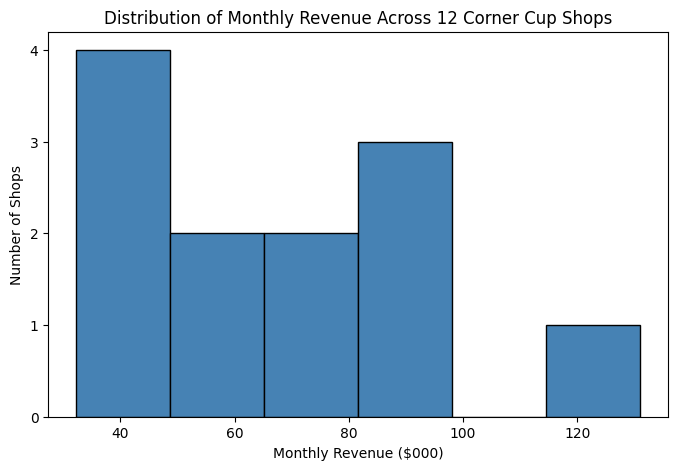

Mean:   71.48
Median: 71.05
Skewness: 0.635


In [5]:
# Chart 1: Histogram of monthly revenue, 6 bins
plt.figure(figsize=(8, 5))
plt.hist(data['Monthly_Revenue_000'], bins=6, color='steelblue',
edgecolor='black')
plt.title('Distribution of Monthly Revenue Across 12 Corner Cup Shops')
plt.xlabel('Monthly Revenue ($000)')
plt.ylabel('Number of Shops')
plt.yticks(range(0, 5))
plt.show()

# Numbers that help describe the shape
print('Mean:  ', round(data['Monthly_Revenue_000'].mean(), 2))
print('Median:', round(data['Monthly_Revenue_000'].median(), 2))
print('Skewness:', round(data['Monthly_Revenue_000'].skew(), 3))



**Interpretation:**

The distribution of monthly revenue is right-skewed (skewness about 0.63). Most shops cluster at the lower end, with 4 shops earning 32K to 49K, while the tail stretches right to Harbour View at 131K, which sits alone in the top bin after an empty bin. Harbour View is a high-performing outlier that pulls the average up.

### Chart 2: Daily Customers vs Monthly Revenue

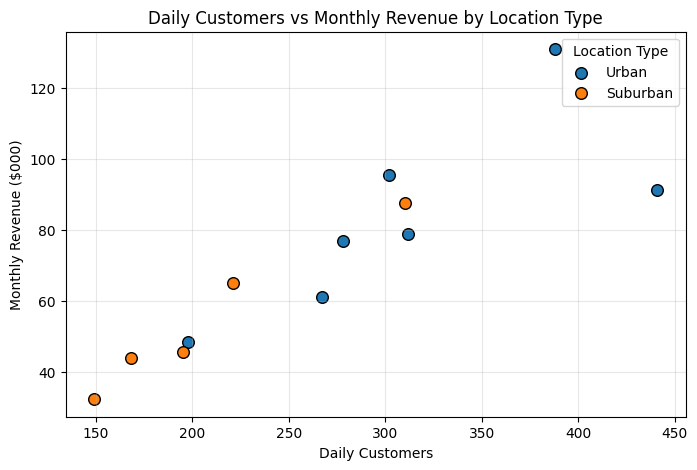

In [6]:
# Chart 2: Daily customers vs monthly revenue, Urban and Suburban in different colours
plt.figure(figsize=(8, 5))
colours = {'Urban': 'tab:blue', 'Suburban': 'tab:orange'}

# Draw one group at a time so each gets its own colour and legend entry
for loc_type, colour in colours.items():
    subset = data[data['Location_Type'] == loc_type]
    plt.scatter(subset['Daily_Customers'], subset['Monthly_Revenue_000'],
                color=colour, label=loc_type, s=70, edgecolor='black')

plt.title('Daily Customers vs Monthly Revenue by Location Type')
plt.xlabel('Daily Customers')
plt.ylabel('Monthly Revenue ($000)')
plt.legend(title='Location Type')
plt.grid(alpha=0.3)
plt.show()

**Interpretation:**

Yes, there is a clear positive relationship: shops with more daily customers tend to earn more (r = 0.877). Urban shops mostly sit in the upper right, while suburban shops sit lower left, except Tech Campus, which performs like an urban shop. Airport Terminal is an outlier: it has the most customers (441) but earns less than Harbour View and Midtown Mall, because its customers spend the least (6.90 dollars each).

### Chart 3: Customer Satisfaction, Urban vs Suburban

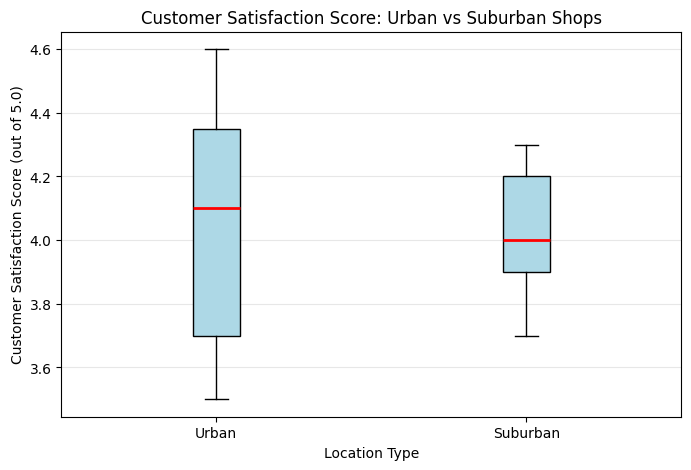

In [7]:
# Chart 3: Box plot of satisfaction scores, Urban vs Suburban
urban = data[data['Location_Type'] == 'Urban']['Customer_Satisfaction_Score']
suburban = data[data['Location_Type'] == 'Suburban']['Customer_Satisfaction_Score']

plt.figure(figsize=(8, 5))
plt.boxplot([urban, suburban], patch_artist=True,
            boxprops=dict(facecolor='lightblue'),
            medianprops=dict(color='red', linewidth=2))
plt.xticks([1, 2], ['Urban', 'Suburban'])
plt.title('Customer Satisfaction Score: Urban vs Suburban Shops')
plt.xlabel('Location Type')
plt.ylabel('Customer Satisfaction Score (out of 5.0)')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [8]:
# Median, quartiles and spread for each group
summary = data.groupby('Location_Type')['Customer_Satisfaction_Score'].describe()
summary['range'] = summary['max'] - summary['min']
summary['IQR'] = summary['75%'] - summary['25%']
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,range,IQR
Location_Type,,,,,,,,,,
Suburban,5.0,4.02,0.24,3.7,3.9,4.0,4.20,4.3,0.6,0.30
Urban,7.0,4.04,0.42,3.5,3.7,4.1,4.35,4.6,1.1,0.65


**Interpretation:**

Urban shops have a slightly higher median satisfaction (4.10 vs 4.00), but the difference is small. Urban scores are far more spread out, from 3.5 (Airport Terminal) to 4.6 (Harbour View), with an interquartile range of 0.65 versus 0.30 for suburban shops. Suburban shops deliver a more consistent experience, while urban results depend heavily on the individual shop.

## B3. Correlation Matrix

In [9]:
# Keep only the six numerical columns, then compute Pearson correlations
numeric_data = data.select_dtypes(include='number')
corr_matrix = numeric_data.corr()
corr_matrix.round(3)

,Floor_Size_sqft,Num_Staff,Daily_Customers,Avg_Spend_per_Customer,Monthly_Revenue_000,Customer_Satisfaction_Score
Floor_Size_sqft,1.000,0.985,0.293,0.913,0.675,0.911
Num_Staff,0.985,1.000,0.309,0.930,0.687,0.876
Daily_Customers,0.293,0.309,1.000,0.237,0.877,0.210
Avg_Spend_per_Customer,0.913,0.930,0.237,1.000,0.661,0.888
Monthly_Revenue_000,0.675,0.687,0.877,0.661,1.000,0.600
Customer_Satisfaction_Score,0.911,0.876,0.210,0.888,0.600,1.000


In [10]:
# Keep each pair once (upper triangle only), then sort by r
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
pairs = corr_matrix.where(mask).stack().sort_values(ascending=False).reset_index()
pairs.columns = ['Variable 1', 'Variable 2', 'r']
pairs['r'] = pairs['r'].round(3)
pairs

,Variable 1,Variable 2,r
0,Floor_Size_sqft,Num_Staff,0.985
1,Num_Staff,Avg_Spend_per_Customer,0.930
2,Floor_Size_sqft,Avg_Spend_per_Customer,0.913
3,Floor_Size_sqft,Customer_Satisfaction_Score,0.911
4,Avg_Spend_per_Customer,Customer_Satisfaction_Score,0.888
5,Daily_Customers,Monthly_Revenue_000,0.877
6,Num_Staff,Customer_Satisfaction_Score,0.876
7,Num_Staff,Monthly_Revenue_000,0.687
8,Floor_Size_sqft,Monthly_Revenue_000,0.675
9,Avg_Spend_per_Customer,Monthly_Revenue_000,0.661


In [11]:
# Each variable's correlation with monthly revenue, highest first
corr_matrix['Monthly_Revenue_000'].drop('Monthly_Revenue_000').sort_values(ascending=False).round(3)

,Monthly_Revenue_000
Daily_Customers,0.877
Num_Staff,0.687
Floor_Size_sqft,0.675
Avg_Spend_per_Customer,0.661
Customer_Satisfaction_Score,0.600


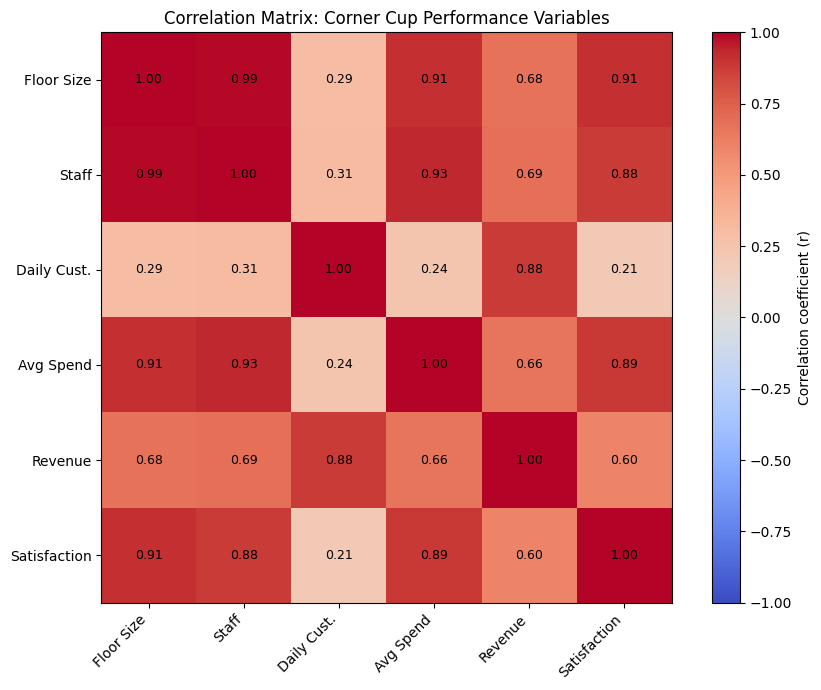

In [12]:
# Colour-coded version of the correlation matrix
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
labels = ['Floor Size', 'Staff', 'Daily Cust.', 'Avg Spend', 'Revenue', 'Satisfaction']
ax.set_xticks(range(6))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(6))
ax.set_yticklabels(labels)

# Write the r value inside each square
for i in range(6):
    for j in range(6):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)

plt.colorbar(im, label='Correlation coefficient (r)')
plt.title('Correlation Matrix: Corner Cup Performance Variables')
plt.tight_layout()
plt.show()

## B3. Correlation Analysis: Findings

**Strongest positive correlations:**
1. Floor_Size_sqft and Num_Staff: r = 0.985. Bigger shops employ more staff.
2. Num_Staff and Avg_Spend_per_Customer: r = 0.930. Better-staffed shops have customers who spend more.

The strongest link to revenue is Daily_Customers and Monthly_Revenue_000 (r = 0.877).

**Weak correlations:**
- Daily_Customers and Customer_Satisfaction_Score: r = 0.210 (the weakest pair)
- Daily_Customers and Avg_Spend_per_Customer: r = 0.237
- Daily_Customers and Floor_Size_sqft: r = 0.293

This tells us that busy shops are not necessarily bigger, and their customers do not spend more or feel more satisfied. Customer traffic and customer experience are separate factors.

**What drives monthly revenue:**
Foot traffic is the strongest driver of monthly revenue at Corner Cup, since Daily_Customers has the highest correlation with revenue (r = 0.877). Revenue is also moderately linked to staff numbers (0.687), floor size (0.675), average spend (0.661) and satisfaction (0.600). These four variables are strongly linked to each other (r between 0.88 and 0.99), which describes a "premium shop": larger, better-staffed shops where customers spend more and are happier. Because traffic and spend are almost unrelated (r = 0.237), they are two separate ways to grow revenue, and the top shops (Harbour View and Midtown Mall) do well on both. With only 12 shops, and because correlation does not prove causation, these are patterns to guide Maya's decisions rather than proof.